# Lab: From Text to BERT — Completed Colab Notebook

This notebook implements the TODOs and includes written-answer drafts for all questions in the supplied lab. **Run every cell in order** so the vocabulary-size measurements, tokenizer comparisons, MLM predictions, and bias-probe charts are produced by the actual models in your session.

## Colab setup
- Recommended: **Runtime → Change runtime type → T4 GPU** (Part C is faster on GPU).
- Internet access is required to download WikiText-2, tokenizer files, and the pretrained BERT weights (~440 MB).
- Save a copy of the executed notebook with its outputs. Exact numeric outputs can vary by library version/hardware.
- The bias probe is a small diagnostic, not proof of real-world system behavior.

The written answers below give the concepts and tell you where to use observed results. For questions asking what your experiment found, verify the numbers and wording against the output produced when you run this notebook.

## 0. Setup

In [1]:
# Uncomment only if a package is missing:
%pip -q install transformers tokenizers datasets matplotlib

import collections
import math
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import datasets
import tokenizers
import transformers
from datasets import load_dataset
from tokenizers import Tokenizer, models, normalizers, pre_tokenizers, trainers
from transformers import AutoTokenizer, AutoModelForMaskedLM, pipeline

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| transformers", transformers.__version__,
      "| tokenizers", tokenizers.__version__, "| datasets", datasets.__version__)
print("device:", device, "(" + torch.cuda.get_device_name(0) + ")" if device.type == "cuda" else "")
if device.type != "cuda":
    print("No GPU detected: Parts A/B are fine; pretrained BERT inference will be slower.")

PyTorch 2.11.0+cpu | transformers 5.20.2 | tokenizers 0.23.3 | datasets 4.8.5
device: cpu 
No GPU detected: Parts A/B are fine; pretrained BERT inference will be slower.


# Part A — Subword tokenization

## Exercise 1 — Apply BPE merges (2 marks)

In [2]:
def bpe_tokenize_word(word, merges, base_vocab, unk_token="[UNK]"):
    """Apply ordered BPE merges to one word and return its pieces."""
    pieces = [ch if ch in base_vocab else unk_token for ch in word]
    for (a, b), merged in merges:
        result = []
        i = 0
        while i < len(pieces):
            if i + 1 < len(pieces) and pieces[i] == a and pieces[i + 1] == b:
                result.append(merged)
                i += 2
            else:
                result.append(pieces[i])
                i += 1
        pieces = result
    return pieces

TOY_BASE_VOCAB = set("bghnpsu")
TOY_MERGES = [(("u", "g"), "ug"), (("u", "n"), "un"), (("h", "ug"), "hug")]
cases = {"hugs": ["hug", "s"], "bug": ["b", "ug"], "pun": ["p", "un"],
         "mug": ["[UNK]", "ug"], "thug": ["[UNK]", "hug"], "unhug": ["un", "hug"]}
for word, expected in cases.items():
    got = bpe_tokenize_word(word, TOY_MERGES, TOY_BASE_VOCAB)
    assert got == expected, f"{word}: expected {expected}, got {got}"
    print(f"{word:6s} -> {got}")
print("Exercise 1 checks passed.")

hugs   -> ['hug', 's']
bug    -> ['b', 'ug']
pun    -> ['p', 'un']
mug    -> ['[UNK]', 'ug']
thug   -> ['[UNK]', 'hug']
unhug  -> ['un', 'hug']
Exercise 1 checks passed.


**Question 1 — Answer.** With `(("h","u"),"hu")` inserted before `(("u","g"),"ug")`, `hug` first becomes `["hu", "g"]`. The `u` has already merged into `hu`, so the later `("u","g")` rule can no longer match. This demonstrates that BPE is defined by its learned merge order; reordering merges changes the segmentation.

## Exercise 2 — WordPiece longest match (2 marks)

In [3]:
def wordpiece_tokenize_word(word, vocab, unk_token="[UNK]", prefix="##"):
    """Greedy longest-match WordPiece; a failed position makes the whole word [UNK]."""
    pieces = []
    start = 0
    while start < len(word):
        end = len(word)
        match = None
        while end > start:
            raw = word[start:end]
            candidate = raw if start == 0 else prefix + raw
            if candidate in vocab:
                match = candidate
                break
            end -= 1
        if match is None:
            return [unk_token]
        pieces.append(match)
        start = end
    return pieces

TOY_WP_VOCAB = {"[UNK]", "b", "h", "p", "u", "##u", "##g", "##n", "##s", "hu", "hug", "##gs", "##un"}
cases = {"hugs": ["hug", "##s"], "bun": ["b", "##un"], "pugs": ["p", "##u", "##gs"],
         "hu": ["hu"], "mug": ["[UNK]"], "hugsx": ["[UNK]"]}
for word, expected in cases.items():
    got = wordpiece_tokenize_word(word, TOY_WP_VOCAB)
    assert got == expected, f"{word}: expected {expected}, got {got}"
    print(f"{word:6s} -> {got}")
print("Exercise 2 checks passed.")

hugs   -> ['hug', '##s']
bun    -> ['b', '##un']
pugs   -> ['p', '##u', '##gs']
hu     -> ['hu']
mug    -> ['[UNK]']
hugsx  -> ['[UNK]']
Exercise 2 checks passed.


**Question 2 — Answer.** BPE's partial fallback can preserve useful known pieces: for `mug`, it retains `ug` even though `m` is unknown. WordPiece's whole-word `[UNK]` behavior is simpler and avoids implying that a partial segmentation is a complete representation. GPT-2's byte-level BPE starts from the finite set of byte values, which can encode any UTF-8 text, so it does not need an `[UNK]` token for unseen characters.

## Exercise 3 — Vocabulary size and sequence length (2 marks)

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

...

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

train paragraphs: 17,556 | validation paragraphs: 1,841
validation example: Homarus gammarus , known as the European lobster or common lobster , is a species of clawed lobster from the eastern Atlantic Ocean , Mediterranean Sea and parts of the Black Sea . It is closely relat ...
Exercise 3 checks passed.
bpe       V= 1,000 fertility=2.861 split_rate=0.601 unk_rate=0.0003
bpe       V= 4,000 fertility=1.407 split_rate=0.258 unk_rate=0.0005
bpe       V=16,000 fertility=1.129 split_rate=0.092 unk_rate=0.0007
wordpiece V= 1,000 fertility=4.300 split_rate=0.835 unk_rate=0.0001
wordpiece V= 4,000 fertility=1.526 split_rate=0.309 unk_rate=0.0002
wordpiece V=16,000 fertility=1.151 split_rate=0.102 unk_rate=0.0003


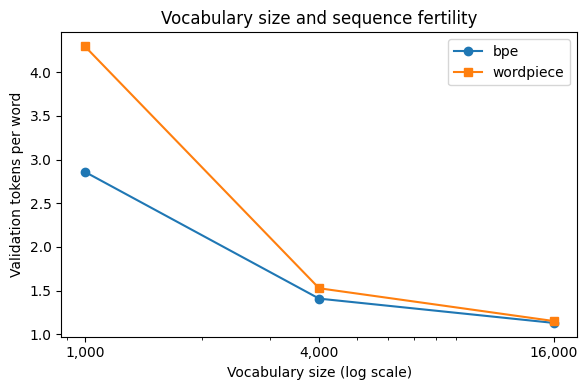


photosynthesis
  bpe        1000: ['p', 'h', 'o', 'to', 's', 'y', 'n', 'the', 's', 'is']
  bpe       16000: ['photo', 'synthesis']
  wordpiece  1000: ['p', '##h', '##o', '##t', '##o', '##s', '##y', '##n', '##t', '##h', '##e', '##s', '##i', '##s']
  wordpiece 16000: ['photos', '##yn', '##the', '##sis']

unbelievably
  bpe        1000: ['un', 'b', 'el', 'i', 'e', 'v', 'a', 'b', 'ly']
  bpe       16000: ['un', 'belie', 'v', 'ably']
  wordpiece  1000: ['u', '##n', '##b', '##e', '##l', '##i', '##e', '##v', '##a', '##b', '##l', '##y']
  wordpiece 16000: ['un', '##bel', '##ie', '##va', '##bl', '##y']

bennett
  bpe        1000: ['b', 'en', 'n', 'e', 't', 't']
  bpe       16000: ['bennett']
  wordpiece  1000: ['b', '##e', '##n', '##n', '##e', '##t', '##t']
  wordpiece 16000: ['bennett']

transformers
  bpe        1000: ['t', 'r', 'an', 's', 'for', 'm', 'er', 's']
  bpe       16000: ['trans', 'form', 'ers']
  wordpiece  1000: ['t', '##r', '##a', '##n', '##s', '##f', '##o', '##r', '##m', '##e',

In [4]:
wiki = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")

def clean(lines):
    return [s.strip() for s in lines if s.strip() and not s.strip().startswith("=")]

train_texts = clean(wiki["train"]["text"])
val_texts = clean(wiki["validation"]["text"])
print(f"train paragraphs: {len(train_texts):,} | validation paragraphs: {len(val_texts):,}")
print("validation example:", val_texts[0][:200], "...")

def train_subword_tokenizer(kind, texts, vocab_size):
    if kind == "bpe":
        tok = Tokenizer(models.BPE(unk_token="[UNK]"))
        trainer = trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=["[UNK]"])
    elif kind == "wordpiece":
        tok = Tokenizer(models.WordPiece(unk_token="[UNK]"))
        trainer = trainers.WordPieceTrainer(vocab_size=vocab_size, special_tokens=["[UNK]"])
    else:
        raise ValueError(kind)
    tok.normalizer = normalizers.Lowercase()
    tok.pre_tokenizer = pre_tokenizers.Whitespace()
    tok.train_from_iterator(texts, trainer=trainer)
    return tok

def subword_stats(tokenizer, texts):
    n_words = n_tokens = n_split = n_unk = 0
    for enc in tokenizer.encode_batch(texts):
        counts = collections.Counter(wid for wid in enc.word_ids if wid is not None)
        n_words += len(counts)
        n_tokens += sum(counts.values())
        n_split += sum(count > 1 for count in counts.values())
        n_unk += sum(token == "[UNK]" for token in enc.tokens)
    if n_words == 0 or n_tokens == 0:
        raise ValueError("No words or tokens found in input text.")
    return {"fertility": n_tokens / n_words,
            "split_rate": n_split / n_words,
            "unk_rate": n_unk / n_tokens}

demo = train_subword_tokenizer("wordpiece", train_texts, vocab_size=4000)
toy = subword_stats(demo, ["tokenization is useful"])
assert set(toy) == {"fertility", "split_rate", "unk_rate"}
assert toy["fertility"] >= 1 and 0 <= toy["split_rate"] <= 1
manual = demo.encode("tokenization is useful")
assert abs(toy["fertility"] - len(manual.tokens) / 3) < 1e-9
print("Exercise 3 checks passed.")

VOCAB_SIZES = [1000, 4000, 16000]
study = {}
for kind in ("bpe", "wordpiece"):
    for size in VOCAB_SIZES:
        tok = train_subword_tokenizer(kind, train_texts, size)
        stats = subword_stats(tok, val_texts)
        study[(kind, size)] = (tok, stats)
        print(f"{kind:9s} V={size:6,d} fertility={stats['fertility']:.3f} "
              f"split_rate={stats['split_rate']:.3f} unk_rate={stats['unk_rate']:.4f}")

fig, ax = plt.subplots(figsize=(6, 4))
for kind, marker in (("bpe", "o"), ("wordpiece", "s")):
    ax.plot(VOCAB_SIZES, [study[(kind, v)][1]["fertility"] for v in VOCAB_SIZES],
            marker=marker, label=kind)
ax.set_xscale("log")
ax.set_xticks(VOCAB_SIZES, [f"{v:,}" for v in VOCAB_SIZES])
ax.set_xlabel("Vocabulary size (log scale)")
ax.set_ylabel("Validation tokens per word")
ax.set_title("Vocabulary size and sequence fertility")
ax.legend()
plt.tight_layout()
plt.show()

for word in ["photosynthesis", "unbelievably", "bennett", "transformers", "kaggle"]:
    print(f"\n{word}")
    for kind in ("bpe", "wordpiece"):
        for size in (1000, 16000):
            print(f"  {kind:9s} {size:5d}: {study[(kind, size)][0].encode(word).tokens}")

**Question 3 — Answer.** (a) Use the printed table to report the actual fertility values for each tokenizer and vocabulary size. In general, a larger vocabulary tends to represent more frequent words/fragments with fewer pieces, reducing fertility and split rate; the measured values are the evidence for this particular corpus. (b) For hidden size \(d\), the embedding table has \(Vd\) parameters: 16,000 tokens need \(16{,}000d\), versus \(1{,}000d\), so the larger table has **16 times** as many parameters (an increase of \(15{,}000d\)). (c) Larger vocabularies can shorten token sequences but increase embedding/softmax parameters and memory. Validation paragraphs estimate performance on held-out text; training on them would contaminate the evaluation.

## Exercise 4 — Three pretrained tokenizers across languages (2 marks)

In [5]:
PRETRAINED = [
    "google-bert/bert-base-uncased",
    "google-bert/bert-base-multilingual-cased",
    "openai-community/gpt2",
]
pretrained_toks = {name: AutoTokenizer.from_pretrained(name) for name in PRETRAINED}
SENTENCES = {
    "English": "I like Indian food very much.",
    "Hindi": "मुझे भारतीय खाना बहुत पसंद है।",
    "Hinglish": "Mujhe Indian khana bahut pasand hai.",
}

def tokens_per_word(tokenizer, text):
    words = len(text.split())
    return len(tokenizer.tokenize(text)) / words if words else 0.0

assert abs(tokens_per_word(pretrained_toks[PRETRAINED[0]], "hello world") -
           len(pretrained_toks[PRETRAINED[0]].tokenize("hello world")) / 2) < 1e-9
print("Exercise 4 checks passed.\n")
print(f"{'Language':10s}" + "".join(f"{n.split('/')[-1]:>32s}" for n in PRETRAINED))
for lang, text in SENTENCES.items():
    print(f"{lang:10s}" + "".join(f"{tokens_per_word(pretrained_toks[n], text):32.2f}" for n in PRETRAINED))
for lang, text in SENTENCES.items():
    print(f"\n{lang}: {text}")
    for name in PRETRAINED:
        tok = pretrained_toks[name]
        pieces = tok.tokenize(text)
        print(f"  {name.split('/')[-1]:32s} {len(pieces):2d} tokens: {pieces}")
        if "uncased" in name:
            print("  decoded back:", repr(tok.decode(tok.encode(text, add_special_tokens=False))))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Exercise 4 checks passed.

Language                 bert-base-uncased    bert-base-multilingual-cased                            gpt2
English                               1.17                            1.17                            1.17
Hindi                                 3.17                            2.17                            7.83
Hinglish                              2.17                            2.00                            2.33

English: I like Indian food very much.
  bert-base-uncased                 7 tokens: ['i', 'like', 'indian', 'food', 'very', 'much', '.']
  decoded back: 'i like indian food very much.'
  bert-base-multilingual-cased      7 tokens: ['I', 'like', 'Indian', 'food', 'very', 'much', '.']
  gpt2                              7 tokens: ['I', 'Ġlike', 'ĠIndian', 'Ġfood', 'Ġvery', 'Ġmuch', '.']

Hindi: मुझे भारतीय खाना बहुत पसंद है।
  bert-base-uncased                19 tokens: ['[UNK]', 'भ', '##ा', '##र', '##त', '##ी', '##य', 'ख', '##ा', '##न', '

**Question 4 — Answer.** (a) Identify the most and least efficient tokenizer for each language from the printed fertility table; the smallest observed value is most efficient and the largest is least efficient for that sentence. (b) Compare the decoded uncased-BERT Hindi string with the original: the English tokenizer's normalization/vocabulary may discard or collapse unsupported Devanagari characters, so the decoded text may not preserve the sentence. (c) A higher tokens-per-word ratio consumes more of a fixed token context window and can raise token-based inference cost. This is only a short three-sentence comparison, not a representative benchmark for all Hindi/Hinglish.

# Part B — Self-attention with a padding mask

## Exercise 5 — Scaled dot-product attention with a mask (3 marks)

In [6]:
def scaled_dot_product_attention(q, k, v, mask=None):
    """q: (B,H,Tq,dk), k/v: (B,H,Tk,dk); bool mask True means allowed."""
    if q.ndim != 4 or k.ndim != 4 or v.ndim != 4:
        raise ValueError("q, k, and v must have shape (B, H, T, d_k)")
    if k.shape != v.shape:
        raise ValueError("k and v must have identical shapes")
    if q.shape[:2] != k.shape[:2] or q.shape[-1] != k.shape[-1]:
        raise ValueError("batch/head dimensions and key depth must match")
    scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(q.size(-1))
    if mask is not None:
        if mask.dtype != torch.bool:
            raise TypeError("mask must be Boolean")
        scores = scores.masked_fill(~mask, float("-inf"))
    weights = torch.softmax(scores, dim=-1)
    output = torch.matmul(weights, v)
    return output, weights

g = torch.Generator().manual_seed(0)
B, H, T, d_k = 2, 3, 5, 4
q, k, v = (torch.randn(B, H, T, d_k, generator=g) for _ in range(3))
lengths = torch.tensor([5, 3])
key_mask = (torch.arange(T)[None, :] < lengths[:, None])[:, None, None, :]
out, w = scaled_dot_product_attention(q, k, v, key_mask)
assert out.shape == (B, H, T, d_k) and w.shape == (B, H, T, T)
assert torch.allclose(w.sum(-1), torch.ones(B, H, T))
assert (w[1, :, :, 3:] == 0).all()
assert torch.allclose(out, F.scaled_dot_product_attention(q, k, v, attn_mask=key_mask), atol=1e-5)
out_nomask, _ = scaled_dot_product_attention(q, k, v)
assert torch.allclose(out_nomask, F.scaled_dot_product_attention(q, k, v), atol=1e-5)
print("Exercise 5 checks passed.")

Exercise 5 checks passed.


## Exercise 6 — The padding mask (1 mark)

In [7]:
def make_padding_mask(input_ids, pad_id):
    """(B,T) IDs -> (B,1,1,T) bool mask, True at real-token keys."""
    if input_ids.ndim != 2:
        raise ValueError("input_ids must have shape (B, T)")
    return (input_ids != pad_id)[:, None, None, :]

ids = torch.tensor([[5, 6, 7, 0, 0], [8, 9, 10, 11, 12]])
m = make_padding_mask(ids, pad_id=0)
assert m.shape == (2, 1, 1, 5) and m.dtype == torch.bool
assert m[0, 0, 0].tolist() == [True, True, True, False, False] and m[1].all()
print("Exercise 6 checks passed.")

Exercise 6 checks passed.


## Provided tiny Transformer encoder and Exercise 7 — Prove padding cannot leak (2 marks)

In [8]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.d_k = n_heads, d_model // n_heads
        self.W_q, self.W_k, self.W_v, self.W_o = (
            nn.Linear(d_model, d_model) for _ in range(4)
        )

    def forward(self, x, mask=None):
        B, T, D = x.shape
        split = lambda t: t.view(B, T, self.h, self.d_k).transpose(1, 2)
        out, weights = scaled_dot_product_attention(
            split(self.W_q(x)), split(self.W_k(x)), split(self.W_v(x)), mask
        )
        return self.W_o(out.transpose(1, 2).reshape(B, T, D)), weights

class EncoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attn = MultiHeadSelfAttention(d_model, n_heads)
        self.ff = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Linear(d_ff, d_model))
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        a, _ = self.attn(x, mask)
        x = self.norm1(x + self.drop(a))
        return self.norm2(x + self.drop(self.ff(x)))

class TinyEncoder(nn.Module):
    def __init__(self, vocab_size, d_model=32, n_heads=4, d_ff=64,
                 n_layers=2, max_len=64, pad_id=0):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        pos = torch.arange(max_len)[:, None]
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
        self.register_buffer("pe", pe)
        self.layers = nn.ModuleList(EncoderLayer(d_model, n_heads, d_ff) for _ in range(n_layers))

    def forward(self, ids, mask=None):
        x = self.emb(ids) * math.sqrt(self.emb.embedding_dim) + self.pe[:ids.size(1)]
        for layer in self.layers:
            x = layer(x, mask)
        return x

@torch.no_grad()
def padding_leakage(model, ids, junk_ids, pad_id, use_mask=True):
    mask = make_padding_mask(ids, pad_id) if use_mask else None
    out_a = model(ids, mask)
    out_b = model(junk_ids, mask)  # same mask for both calls
    real = (ids != pad_id).unsqueeze(-1).expand_as(out_a)
    return float((out_a - out_b).abs()[real].max().item()) if real.any() else 0.0

torch.manual_seed(SEED)
encoder = TinyEncoder(vocab_size=50).eval()
ids = torch.tensor([[7, 8, 9, 0, 0, 0], [10, 11, 12, 13, 14, 0]])
junk_ids = ids.clone()
junk_ids[ids == 0] = torch.tensor([31, 32, 33, 34])
with_mask = padding_leakage(encoder, ids, junk_ids, pad_id=0, use_mask=True)
without_mask = padding_leakage(encoder, ids, junk_ids, pad_id=0, use_mask=False)
print(f"with mask   : max change at real positions = {with_mask:.2e}")
print(f"without mask: max change at real positions = {without_mask:.2e}")
assert with_mask < 1e-5
assert without_mask > 1e-3
print("Exercise 7 checks passed.")

with mask   : max change at real positions = 0.00e+00
without mask: max change at real positions = 7.28e-01
Exercise 7 checks passed.


**Question 5 — Answer.** (a) Input IDs: `(2, 6)`; embeddings: `(2, 6, 32)`; queries after splitting into four heads: `(2, 4, 6, 8)`; attention weights: `(2, 4, 6, 6)`; encoder output: `(2, 6, 32)`. (b) Padding positions can still form query outputs, but the padding mask prevents real tokens from using padded positions as keys/values. BERT's loss and downstream pooling/classification use the meaningful non-padding tokens, so padded query outputs are ignored. (c) BERT is bidirectional: a masked token can use both left and right context, so it uses a padding mask but no causal mask. GPT-2 predicts the next token and must not see future tokens, so it uses both a padding mask (when needed) and a causal mask.

**Exercise 7 interpretation.** With the mask, changing only padded token IDs should leave real-token outputs unchanged (numerical difference near zero). Without the mask, real tokens can attend to those positions, so the output should change.

# Part C — BERT: inputs, objective, and predictions

The next cell downloads pretrained BERT-base weights (about 440 MB).

In [9]:
BERT = "google-bert/bert-base-uncased"
bert_tok = AutoTokenizer.from_pretrained(BERT)
bert_mlm = AutoModelForMaskedLM.from_pretrained(BERT).to(device).eval()
print("vocabulary size:", bert_tok.vocab_size,
      "| parameters:", round(sum(p.numel() for p in bert_mlm.parameters()) / 1e6, 1), "M")
print("special tokens:", {t: bert_tok.convert_tokens_to_ids(t)
      for t in ["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"]})

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: google-bert/bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.bias      | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


vocabulary size: 30522 | parameters: 109.5 M
special tokens: {'[PAD]': 0, '[UNK]': 100, '[CLS]': 101, '[SEP]': 102, '[MASK]': 103}


## Exercise 8 — BERT's three input tensors (2 marks)

In [10]:
pair = bert_tok("The cat sat on the mat.", "It looked very comfortable.",
                 padding="max_length", max_length=20, return_tensors="pt")
print(f"{'pos':>3}  {'token':12s} {'input_id':>8} {'type':>4} {'attn':>4}")
for i, (tid, tt, am) in enumerate(zip(pair["input_ids"][0], pair["token_type_ids"][0], pair["attention_mask"][0])):
    print(f"{i:3d}  {bert_tok.convert_ids_to_tokens(int(tid)):12s} {int(tid):8d} {int(tt):4d} {int(am):4d}")

def describe_bert_input(enc, tokenizer):
    """Summarize one encoded sentence pair (batch size 1)."""
    ids, types, attn = enc["input_ids"][0], enc["token_type_ids"][0], enc["attention_mask"][0]
    cls_id, sep_id, pad_id = tokenizer.cls_token_id, tokenizer.sep_token_id, tokenizer.pad_token_id
    cls_positions = (ids == cls_id).nonzero(as_tuple=True)[0].tolist()
    sep_positions = (ids == sep_id).nonzero(as_tuple=True)[0].tolist()
    segment_b_tokens = int(((types == 1) & (attn == 1)).sum().item())
    pad_tokens = int((attn == 0).sum().item())
    return {"cls_position": cls_positions[0] if cls_positions else None,
            "sep_positions": sep_positions,
            "segment_b_tokens": segment_b_tokens,
            "pad_tokens": pad_tokens}

info = describe_bert_input(pair, bert_tok)
print(info)
tokens_b = bert_tok.tokenize("It looked very comfortable.")
assert info["cls_position"] == 0
assert len(info["sep_positions"]) == 2
assert info["segment_b_tokens"] == len(tokens_b) + 1
assert info["pad_tokens"] == 20 - (info["sep_positions"][-1] + 1)
print("Exercise 8 checks passed.")

pos  token        input_id type attn
  0  [CLS]             101    0    1
  1  the              1996    0    1
  2  cat              4937    0    1
  3  sat              2938    0    1
  4  on               2006    0    1
  5  the              1996    0    1
  6  mat             13523    0    1
  7  .                1012    0    1
  8  [SEP]             102    0    1
  9  it               2009    1    1
 10  looked           2246    1    1
 11  very             2200    1    1
 12  comfortable      6625    1    1
 13  .                1012    1    1
 14  [SEP]             102    1    1
 15  [PAD]               0    0    0
 16  [PAD]               0    0    0
 17  [PAD]               0    0    0
 18  [PAD]               0    0    0
 19  [PAD]               0    0    0
{'cls_position': 0, 'sep_positions': [8, 14], 'segment_b_tokens': 6, 'pad_tokens': 5}
Exercise 8 checks passed.


**Question 6 — Answer.** The first `[SEP]` marks the end of sentence A; the second marks the end of sentence B. Padding positions typically have `token_type_ids = 0`, but they are excluded by `attention_mask = 0`, so they should not contribute as real input tokens. For sentence-pair classification, the final `[CLS]` hidden state is commonly passed to a classification head to predict a label such as entailment/contradiction or a class category.

## Exercise 9 — BERT's 80/10/10 masking rule (4 marks)

In [11]:
wiki = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")
val_texts = clean(wiki["validation"]["text"])
mlm_batch = bert_tok(val_texts[:512], padding=True, truncation=True, max_length=128,
                     return_tensors="pt", return_special_tokens_mask=True)
special_mask = mlm_batch["special_tokens_mask"].bool() | (mlm_batch["attention_mask"] == 0)
print("batch shape:", tuple(mlm_batch["input_ids"].shape),
      "| eligible tokens:", int((~special_mask).sum()))

def mask_tokens(input_ids, special_mask, mask_token_id, vocab_size, mlm_prob=0.15, generator=None):
    """BERT MLM masking; does not modify input_ids. Returns (masked_ids, labels)."""
    if input_ids.shape != special_mask.shape:
        raise ValueError("input_ids and special_mask must have the same shape")
    eligible = ~special_mask.bool()
    select = torch.bernoulli(torch.full(input_ids.shape, mlm_prob, dtype=torch.float,
                                         device=input_ids.device), generator=generator).bool() & eligible
    labels = input_ids.clone()
    labels[~select] = -100
    masked_ids = input_ids.clone()

    replace_mask = (torch.bernoulli(torch.full(input_ids.shape, 0.8, dtype=torch.float,
                                               device=input_ids.device), generator=generator).bool() & select)
    masked_ids[replace_mask] = mask_token_id

    remaining = select & ~replace_mask
    random_replace = (torch.bernoulli(torch.full(input_ids.shape, 0.5, dtype=torch.float,
                                                 device=input_ids.device), generator=generator).bool() & remaining)
    random_ids = torch.randint(vocab_size, input_ids.shape, generator=generator,
                               device=input_ids.device, dtype=input_ids.dtype)
    masked_ids[random_replace] = random_ids[random_replace]
    return masked_ids, labels

original = mlm_batch["input_ids"].clone()
masked_ids, labels = mask_tokens(mlm_batch["input_ids"], special_mask, bert_tok.mask_token_id,
                                 bert_tok.vocab_size, mlm_prob=0.15,
                                 generator=torch.Generator().manual_seed(SEED))
assert torch.equal(mlm_batch["input_ids"], original), "input_ids was modified in place"
selected = labels != -100
assert not (selected & special_mask).any()
assert torch.equal(labels[selected], original[selected])
assert torch.equal(masked_ids[~selected], original[~selected])
eligible_count = int((~special_mask).sum())
n_sel = int(selected.sum())
is_mask = (masked_ids == bert_tok.mask_token_id) & selected
is_unchanged = (masked_ids == original) & selected
is_random = selected & ~is_mask & ~is_unchanged
frac = lambda m: int(m.sum()) / max(n_sel, 1)
print(f"selected: {n_sel / eligible_count:.3f} of eligible tokens (target 0.15)")
print(f"of selected -> [MASK]: {frac(is_mask):.3f} (0.8) | random: {frac(is_random):.3f} (~0.1) | unchanged: {frac(is_unchanged):.3f} (~0.1)")
assert abs(n_sel / eligible_count - 0.15) < 0.01
assert abs(frac(is_mask) - 0.8) < 0.03 and abs(frac(is_random) - 0.1) < 0.03 and abs(frac(is_unchanged) - 0.1) < 0.03
print("Exercise 9 checks passed.")

batch shape: (512, 128) | eligible tokens: 44242
selected: 0.148 of eligible tokens (target 0.15)
of selected -> [MASK]: 0.792 (0.8) | random: 0.105 (~0.1) | unchanged: 0.103 (~0.1)
Exercise 9 checks passed.


**Question 7 — Answer.** (a) Replacing every selected token with `[MASK]` would make pretraining inputs look unlike ordinary text, where `[MASK]` is usually absent; the model could over-rely on that artificial cue. (b) Leaving some selected tokens unchanged exposes the model to normal-looking inputs while still asking it to predict those tokens. Random replacements teach it to recover the original token even when the observed token is misleading and reduce dependence on `[MASK]`. (c) A random draw can coincidentally equal the original token. That event is rare for a large vocabulary and does not meaningfully change the intended stochastic 80/10/10 procedure; it only slightly affects the observed category fractions.

## Exercise 10 — BERT's top-k predictions (3 marks)

In [12]:
@torch.no_grad()
def top_k_predictions(text, k=5):
    """Return [(token_string, probability), ...] for exactly one [MASK]."""
    if k < 1 or k > bert_tok.vocab_size:
        raise ValueError("k must be between 1 and vocabulary size")
    enc = bert_tok(text, return_tensors="pt").to(device)
    mask_positions = (enc["input_ids"][0] == bert_tok.mask_token_id).nonzero(as_tuple=True)[0]
    if len(mask_positions) != 1:
        raise ValueError("text must contain exactly one [MASK] token")
    logits = bert_mlm(**enc).logits
    pos = int(mask_positions.item())
    probs = torch.softmax(logits[0, pos], dim=-1)
    top_probs, top_ids = torch.topk(probs, k)
    return [(bert_tok.convert_ids_to_tokens(int(tid)), float(prob))
            for tid, prob in zip(top_ids.cpu(), top_probs.cpu())]

preds = top_k_predictions("The cat sat on the [MASK].", k=5)
print(preds)
probs_ = [p for _, p in preds]
assert len(preds) == 5 and probs_ == sorted(probs_, reverse=True) and 0 < sum(probs_) <= 1 + 1e-6
fill = pipeline("fill-mask", model=bert_mlm, tokenizer=bert_tok,
                device=0 if device.type == "cuda" else -1)
ref = fill("The cat sat on the [MASK].", top_k=1)[0]
assert bert_tok.convert_tokens_to_ids(preds[0][0]) == ref["token"]
assert abs(preds[0][1] - ref["score"]) < 1e-3
print("Exercise 10 checks passed.\n")

for text in ["Paris is the capital of [MASK].",
             "She opened the [MASK] and walked into the room.",
             "The doctor gave me some [MASK] for my headache.",
             "Bennett University is located in [MASK]."]:
    print(f"{text:50s}", [(t, round(p, 3)) for t, p in top_k_predictions(text)])

[('floor', 0.31445834040641785), ('bed', 0.11902324855327606), ('couch', 0.10695988684892654), ('sofa', 0.06032621115446091), ('ground', 0.055082179605960846)]
Exercise 10 checks passed.

Paris is the capital of [MASK].                    [('france', 0.951), ('algeria', 0.012), ('morocco', 0.003), ('reunion', 0.003), ('haiti', 0.003)]
She opened the [MASK] and walked into the room.    [('door', 0.987), ('doors', 0.003), ('window', 0.001), ('curtain', 0.001), ('curtains', 0.001)]
The doctor gave me some [MASK] for my headache.    [('medication', 0.274), ('medicine', 0.088), ('treatment', 0.079), ('help', 0.075), ('water', 0.072)]
Bennett University is located in [MASK].           [('bennett', 0.185), ('omaha', 0.035), ('sacramento', 0.031), ('burlington', 0.026), ('nashville', 0.023)]


## Provided — MLM recovery evaluation

The code below measures top-1 recovery separately for positions observed as `[MASK]`, random replacements, and unchanged selected tokens. Unchanged positions are a special case: the original word is already visible to the model.

In [13]:
@torch.no_grad()
def mlm_eval(masked_ids, labels, attention_mask, batch_size=64):
    correct = {"[MASK]": 0, "random": 0, "unchanged": 0}
    total = dict.fromkeys(correct, 0)
    loss_sum, selected_count = 0.0, 0
    for start in range(0, masked_ids.size(0), batch_size):
        ids_b = masked_ids[start:start + batch_size].to(device)
        lab_b = labels[start:start + batch_size].to(device)
        att_b = attention_mask[start:start + batch_size].to(device)
        out = bert_mlm(input_ids=ids_b, attention_mask=att_b, labels=lab_b)
        n = int((lab_b != -100).sum())
        loss_sum += float(out.loss) * n
        selected_count += n
        pred = out.logits.argmax(-1)
        sel = lab_b != -100
        kinds = {"[MASK]": sel & (ids_b == bert_tok.mask_token_id),
                 "unchanged": sel & (ids_b == lab_b)}
        kinds["random"] = sel & ~kinds["[MASK]"] & ~kinds["unchanged"]
        for name, m in kinds.items():
            correct[name] += int((pred[m] == lab_b[m]).sum())
            total[name] += int(m.sum())
    for name in correct:
        print(f"{name:10s} positions: {total[name]:6d}   top-1 accuracy = {correct[name] / max(total[name], 1):.3f}")
    print(f"selected-token mean MLM loss = {loss_sum / max(selected_count, 1):.3f} nats/token")

mlm_eval(masked_ids, labels, mlm_batch["attention_mask"])

[MASK]     positions:   5196   top-1 accuracy = 0.612
random     positions:    690   top-1 accuracy = 0.477
unchanged  positions:    677   top-1 accuracy = 0.965
selected-token mean MLM loss = 2.136 nats/token


**Question 8 — Answer.** Usually unchanged selected positions have the highest apparent accuracy because the correct token remains visible; this can make the task close to copying. `[MASK]` positions have a dedicated cue that prediction is required, while random-replacement positions contain a potentially misleading token, so their accuracy may be lower. Quote the actual ranking from your run because stochastic masking can change the exact values. Reporting unchanged-position accuracy as evidence that BERT “understands” text would be misleading: the answer is already present in the input, and the model may simply copy it rather than infer it from context.

## Exercise 11 — A careful bias probe (2 marks)

Exercise 11 checks passed.


Template: the {occ} said that [MASK] was tired.
  nurse         P(he)=0.187044 P(she)=0.636523 log ratio=-1.225
  receptionist  P(he)=0.0745044 P(she)=0.815043 log ratio=-2.392
  teacher       P(he)=0.466576 P(she)=0.376857 log ratio=+0.214
  doctor        P(he)=0.479886 P(she)=0.327787 log ratio=+0.381
  engineer      P(he)=0.819809 P(she)=0.0525315 log ratio=+2.748
  pilot         P(he)=0.855071 P(she)=0.0809174 log ratio=+2.358
  programmer    P(he)=0.78766 P(she)=0.111406 log ratio=+1.956
  scientist     P(he)=0.69061 P(she)=0.141887 log ratio=+1.583

Template: after the meeting, the {occ} explained why [MASK] had to leave early.
  nurse         P(he)=0.0853596 P(she)=0.354712 log ratio=-1.424
  receptionist  P(he)=0.101512 P(she)=0.429722 log ratio=-1.443
  teacher       P(he)=0.327001 P(she)=0.272625 log ratio=+0.182
  doctor        P(he)=0.533993 P(she)=0.0808374 log ratio=+1.888
  engineer      P(he)=0.526741 P(she)=0.0256502 log ratio=+3.022
  pilo

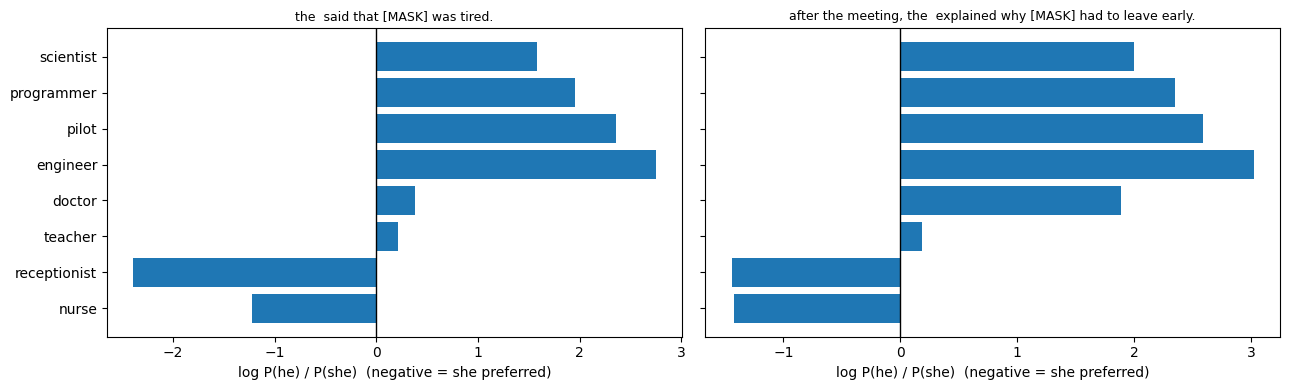

In [14]:
@torch.no_grad()
def pronoun_probs(sentence):
    """Return full-vocabulary softmax probabilities for 'he' and 'she' at one [MASK]."""
    enc = bert_tok(sentence, return_tensors="pt").to(device)
    positions = (enc["input_ids"][0] == bert_tok.mask_token_id).nonzero(as_tuple=True)[0]
    if len(positions) != 1:
        raise ValueError("sentence must contain exactly one [MASK]")
    logits = bert_mlm(**enc).logits
    pos = int(positions.item())
    probs = torch.softmax(logits[0, pos], dim=-1)
    he_id = bert_tok.convert_tokens_to_ids("he")
    she_id = bert_tok.convert_tokens_to_ids("she")
    return float(probs[he_id]), float(probs[she_id])

p_he, p_she = pronoun_probs("Yesterday [MASK] went to the market.")
assert 0 <= p_he <= 1 and 0 <= p_she <= 1 and p_he + p_she <= 1 + 1e-6
print("Exercise 11 checks passed.\n")

OCCUPATIONS = ["nurse", "receptionist", "teacher", "doctor", "engineer", "pilot", "programmer", "scientist"]
TEMPLATES = ["the {occ} said that [MASK] was tired.",
             "after the meeting, the {occ} explained why [MASK] had to leave early."]
fig, axes = plt.subplots(1, len(TEMPLATES), figsize=(13, 4), sharey=True)
for ax, template in zip(axes, TEMPLATES):
    log_ratios = []
    print("\nTemplate:", template)
    for occ in OCCUPATIONS:
        he, she = pronoun_probs(template.format(occ=occ))
        # clamp only to avoid log(0) due to floating-point underflow
        ratio = math.log(max(he, 1e-30) / max(she, 1e-30))
        log_ratios.append(ratio)
        print(f"  {occ:13s} P(he)={he:.6g} P(she)={she:.6g} log ratio={ratio:+.3f}")
    ax.barh(OCCUPATIONS, log_ratios)
    ax.axvline(0, color="black", lw=1)
    ax.set_xlabel("log P(he) / P(she)  (negative = she preferred)")
    ax.set_title(template.replace("{occ}", ""), fontsize=9)
plt.tight_layout()
plt.show()

**Question 9 — Answer.** (a) Read both charts and printed log-ratios: a positive value means the model assigns higher probability to `he`, while a negative value means it assigns higher probability to `she`. Compare the ordering across the two templates; do not assume rankings match, because context wording changes masked-token probabilities. (b) This experiment does not establish real-world bias because: **(1)** it uses only eight occupations, two hand-written templates, and two pronouns; **(2)** token probabilities depend strongly on sentence wording and syntax; **(3)** a masked-language-model probability is not the same as a deployed system's decision or behavior; **(4)** results may vary across model versions, training data, languages, and social groups; and **(5)** it omits nonbinary pronouns and intersectional/contextual factors. (c) Improve reliability by using many pre-registered, balanced templates and a broader set of occupations/pronouns, running multiple paraphrases, reporting uncertainty and effect sizes, and comparing results across models/datasets. A probe can reveal a limited association, not by itself prove how biased a system is in practice.